<div style="background-color:#000000; padding:34px 38px 30px 38px; border-radius:14px;">
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#A6A6A6; margin:0; font-size:0.85em; font-weight:600; letter-spacing:0.16em;">CHARMM FORCE FIELD · ALKYLSILANE MONOLAYERS ON SILICA</p>
<h1 style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#ffffff; margin:12px 0 14px 0; font-size:2.2em; font-weight:700; line-height:1.15; letter-spacing:-0.01em;">Force-field parameterization of the Si–C bond<br>in octylsilanetriol: length and force constant</h1>
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#E0E0E0; margin:0; font-size:1.12em; font-weight:400; line-height:1.55;">The bond between the silicon and the first carbon of the alkyl chain has no CHARMM parameters. Its length comes from an ORCA relaxation, and its force constant is calculated in two ways: reduced-mass scaling of the CHARMM <span style="white-space:nowrap;">C–C</span> bond, and ORCA bond scans calibrated on CHARMM.</p>
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#BDBDBD; margin:18px 0 0 0; font-size:0.95em; font-weight:500;">Model molecule: octylsilanetriol, Si(OH)<sub>3</sub>–C<sub>8</sub>H<sub>17</sub> (alkylsilane with <i>L</i> = 8), neutral, in the gas phase, not bonded to a surface · HF/6-31G* · ORCA</p>
</div>

<div style="text-align:center"><img src="figures/molecule.png" width="720"></div>

Method 1 scales the CHARMM C–C force constant by the reduced masses. Method 2 uses relaxed scans of the Si<sub>anc</sub>–C<sub>1</sub> and C–C bonds at the HF/6-31G\* level [1, 2] with ORCA [3, 4] and calibrates them on the CHARMM C–C bond. Relaxed structure: `ORCA_results/relaxation`; scans: `ORCA_results/bond_scans`. The results can be used, for example, in molecular dynamics simulations of alkylsilanes on silica.

<p>Section colors: <span style="background-color:#2A9D8F; color:#ffffff; padding:2px 9px; border-radius:10px;">molecule</span> <span style="background-color:#6C757D; color:#ffffff; padding:2px 9px; border-radius:10px;">method 1</span> <span style="background-color:#0D4F8B; color:#ffffff; padding:2px 9px; border-radius:10px;">method 2</span> <span style="background-color:#756BB1; color:#ffffff; padding:2px 9px; border-radius:10px;">other estimates</span> <span style="background-color:#2E7D57; color:#ffffff; padding:2px 9px; border-radius:10px;">comparison</span></p>

In [1]:
%pip install -q numpy pandas matplotlib ase nglview ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import nglview
import numpy as np
import pandas as pd
from ase import Atoms
from ase.io import read
import ipywidgets as widgets


RELAXED = Path('ORCA_results/relaxation')
SCANS = Path('ORCA_results/bond_scans')
HARTREE = 2625.4996
BOHR = 0.052917721
M_C, M_SI = 12.011, 28.0855
COLORS = {'Si–C': '#B7371B', 'C–C': '#0D4F8B'}
LABELS = {'Si–C': r'Si$_{\rm anc}$–C$_1$', 'C–C': r'C$_4$–C$_5$'}

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial'], 'font.size': 9,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'xtick.direction': 'in', 'ytick.direction': 'in', 'legend.frameon': False})

<h2 style="background-color:#2A9D8F; color:#ffffff; padding:8px 14px; border-radius:6px;">Molecule: relaxation of the model molecule<br><span style="font-size:0.72em; font-weight:normal;">Si(OH)<sub>3</sub>–C<sub>8</sub>H<sub>17</sub>, alkylsilane with <i>L</i> = 8, HF/6-31G*, ORCA</span></h2>

ORCA relaxes the start structure (`octylsilanetriol_start.xyz`) to the relaxed structure (`octylsilanetriol.xyz`), both in `ORCA_results/relaxation`. Play the optimization steps with the buttons below the view; turn and zoom with the mouse [5, 6].

In [ ]:
def read_frames(path):
    lines = Path(path).read_text().split('\n')
    frames = []
    i = 0
    while i < len(lines):
        if lines[i].strip().isdigit():
            n = int(lines[i])
            symbols = []
            positions = []
            for line in lines[i + 2:i + 2 + n]:
                parts = line.split()
                symbols.append(parts[0])
                positions.append([float(parts[1]), float(parts[2]), float(parts[3])])
            frames.append(Atoms(symbols, positions))
            i = i + n + 2
        else:
            i = i + 1
    return frames


def show_frames(path, label='point'):
    view = nglview.show_asetraj(read_frames(path))
    view.background = 'white'
    play = widgets.Play(max=view.max_frame, interval=200)
    slider = widgets.IntSlider(max=view.max_frame, description=label)
    widgets.jslink((play, 'value'), (slider, 'value'))
    widgets.jslink((slider, 'value'), (view, 'frame'))
    return widgets.VBox([view, widgets.HBox([play, slider])])


show_frames(RELAXED / 'octylsilanetriol_trj.xyz', 'step')

The Si<sub>anc</sub>–C<sub>1</sub> bond in the final table of the ORCA output (atoms 7 and 0, counted from 0; last column: relaxed value in Å):

In [4]:
lines = (RELAXED / 'octylsilanetriol.out').read_text().split('\n')
for i in range(len(lines)):
    if 'B(C   7,Si  0)' in lines[i]:
        number = i

print(f'line {number + 1} of octylsilanetriol.out:')
print(lines[number])
length = float(lines[number].split()[-1]) / 10
print(f'Si-C1 length: {length:.5f} nm, rounded {length:.3f} nm')

line 3330 of octylsilanetriol.out:
     7. B(C   7,Si  0)                1.8647 -0.000003  0.0000    1.8647   
Si-C1 length: 0.18647 nm, rounded 0.186 nm


Bond lengths and force constants before the scans. CHARMM has no parameters for the Si<sub>anc</sub>–C<sub>1</sub> bond; the relaxation gives its length, but not its force constant $k$, which the next sections compute.

In [5]:
molecule = read(RELAXED / 'octylsilanetriol.xyz')
symbols = molecule.get_chemical_symbols()
silicon = symbols.index('Si')
carbons = []
for i in range(len(symbols)):
    if symbols[i] == 'C':
        carbons.append(i)

b0_cc_charmm = 0.1530
k_cc_charmm = 2 * 222.50 * 4.184 * 100
length_cc = molecule.get_distance(carbons[3], carbons[4]) / 10
length_sic = molecule.get_distance(silicon, carbons[0]) / 10

table = pd.DataFrame(index=['C–C (C₄–C₅)', 'Si–C (Si–C₁)'])
table['CHARMM: length (nm)'] = [f'{b0_cc_charmm:.4f}', '']
table['CHARMM: k (kJ/mol/nm²)'] = [f'{k_cc_charmm:,.0f}', '']
table['ORCA, HF/6-31G*: length (nm)'] = [f'{length_cc:.5f}', f'{length_sic:.5f}']
table['ORCA, HF/6-31G*: k (kJ/mol/nm²)'] = ['', '']
table

,CHARMM: length (nm),CHARMM: k (kJ/mol/nm²),"ORCA, HF/6-31G*: length (nm)","ORCA, HF/6-31G*: k (kJ/mol/nm²)"
C–C (C₄–C₅),0.1530,"186,188",0.15298,
Si–C (Si–C₁),,,0.18647,


<h2 style="background-color:#6C757D; color:#ffffff; padding:8px 14px; border-radius:6px;">Method 1: reduced-mass scaling<br><span style="font-size:0.72em; font-weight:normal;">the CHARMM C–C force constant scaled by the reduced masses</span></h2>

<div style="text-align:center"><img src="figures/method_1_bonds.png" width="640"></div>

CHARMM C–C bond [7]: $K_b = 222.50$ kcal mol⁻¹ Å⁻² with $V = K_b (r - b_0)^2$. GROMACS uses $V = \frac{1}{2} k (r - b_0)^2$, so $k = 2 K_b$. Reduced-mass scaling multiplies it by the ratio of the reduced masses:

$$k_{\rm Si-C} = k_{\rm C-C}^{\rm CHARMM}\,\frac{\mu_{\rm C-C}}{\mu_{\rm Si-C}}, \qquad \mu_{\rm AB} = \frac{m_{\rm A}m_{\rm B}}{m_{\rm A}+m_{\rm B}}$$

In [6]:
mu_cc = M_C * M_C / (M_C + M_C)
mu_sic = M_SI * M_C / (M_SI + M_C)
k_mass = k_cc_charmm * mu_cc / mu_sic

print(f'k C-C (CHARMM): {k_cc_charmm:,.0f} kJ/mol/nm2, rounded {k_cc_charmm:.4e} kJ/mol/nm2')
print(f'mu C-C = {mu_cc:.4f} u, mu Si-C = {mu_sic:.5f} u, ratio = {mu_cc / mu_sic:.6f}')
print(f'k Si-C (reduced-mass scaling): {k_mass:,.0f} kJ/mol/nm2, rounded {k_mass:.4e} kJ/mol/nm2')

k C-C (CHARMM): 186,188 kJ/mol/nm2, rounded 1.8619e+05 kJ/mol/nm2
mu C-C = 6.0055 u, mu Si-C = 8.41308 u, ratio = 0.713829
k Si-C (reduced-mass scaling): 132,906 kJ/mol/nm2, rounded 1.3291e+05 kJ/mol/nm2


<h2 style="background-color:#0D4F8B; color:#ffffff; padding:8px 14px; border-radius:6px;">Method 2: relaxed bond scans<br><span style="font-size:0.72em; font-weight:normal;">the scans of the Si<sub>anc</sub>–C<sub>1</sub> and C–C bonds</span></h2>

<div style="text-align:center"><img src="figures/scanned_bonds.png" width="640"></div>

Two bonds are scanned: Si<sub>anc</sub>–C<sub>1</sub> and the C₄–C₅ bond of the chain. At every point the bond length is fixed and the rest of the molecule is optimized. Play the 50 structures of each scan with the buttons below the view.

In [7]:
def read_scan(path):
    r, energy = np.loadtxt(path, unpack=True)
    r = r / 10
    e = (energy - energy.min()) * HARTREE
    return r, e


scans = {}
scans['Si–C'] = read_scan(SCANS / 'Si-C' / 'si_c_scan.relaxscanact.dat')
scans['C–C'] = read_scan(SCANS / 'C4-C5' / 'c4_c5_scan.relaxscanact.dat')
for bond in scans:
    r, e = scans[bond]
    print(f'{bond}: {len(r)} points from {r[0]:.4f} to {r[-1]:.4f} nm, lowest point at {r[np.argmin(e)]:.5f} nm')

Si–C: 50 points from 0.1800 to 0.1940 nm, lowest point at 0.18657 nm
C–C: 50 points from 0.1450 to 0.1590 nm, lowest point at 0.15300 nm


In [ ]:
show_frames(SCANS / 'Si-C' / 'si_c_scan.allxyz')

In [ ]:
show_frames(SCANS / 'C4-C5' / 'c4_c5_scan.allxyz')

<h2 style="background-color:#0D4F8B; color:#ffffff; padding:8px 14px; border-radius:6px;">Method 2: relaxed bond scans<br><span style="font-size:0.72em; font-weight:normal;">force constants from the curvature at the minimum</span></h2>

Cubic fit to the 9 points around the lowest point. The force constant is the second derivative at the minimum, $k = d^2E/dr^2$, the $k$ of $E = \frac{1}{2}k(r-r_0)^2$.

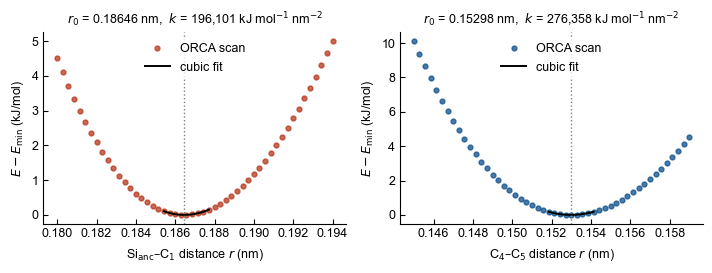

In [10]:
def curvature(r, e, half=4):
    low = np.argmin(e)
    part = slice(low - half, low + half + 1)
    fit = np.polyfit(r[part], e[part], 3)
    slope = np.polyder(fit)
    bend = np.polyder(fit, 2)
    for root in np.roots(slope):
        if abs(root.imag) < 1e-12 and np.polyval(bend, root.real) > 0:
            r0 = root.real
    k = np.polyval(bend, r0)
    return r0, k, fit, part


def plot_scans(scans, fits):
    names = list(scans)
    fig, axes = plt.subplots(1, len(names), figsize=(3.6 * len(names), 2.8), squeeze=False)
    for i in range(len(names)):
        bond = names[i]
        ax = axes[0, i]
        r, e = scans[bond]
        r0, k, fit, part = fits[bond]
        x = np.linspace(r[part][0], r[part][-1], 100)
        ax.plot(r, e, 'o', ms=3.5, color=COLORS[bond], alpha=0.75, label='ORCA scan')
        ax.plot(x, np.polyval(fit, x), color='black', lw=1.4, label='cubic fit')
        ax.axvline(r0, color='gray', ls=':', lw=1)
        ax.set_xlabel(f'{LABELS[bond]} distance $r$ (nm)')
        ax.set_ylabel(r'$E - E_{\rm min}$ (kJ/mol)')
        ax.set_title(f'$r_0$ = {r0:.5f} nm,  $k$ = {k:,.0f} kJ mol$^{{-1}}$ nm$^{{-2}}$', fontsize=9)
        ax.legend(loc='upper center', frameon=True, facecolor='white', edgecolor='none')
    fig.tight_layout()
    # fig.savefig('figures/bond_scans.pdf')
    plt.show()


fits = {}
for bond in scans:
    r, e = scans[bond]
    fits[bond] = curvature(r, e)
plot_scans(scans, fits)

The result does not depend on the number of fitted points ($k$ in kJ mol⁻¹ nm⁻²):


In [11]:
table = pd.DataFrame(index=list(scans))
for half in [3, 4, 6, 8]:
    values = []
    for bond in scans:
        r, e = scans[bond]
        values.append(round(curvature(r, e, half)[1]))
    table[f'{2 * half + 1} points'] = values
table

,7 points,9 points,13 points,17 points
Si–C,196055,196101,196165,196234
C–C,276290,276358,276447,276559


<h2 style="background-color:#0D4F8B; color:#ffffff; padding:8px 14px; border-radius:6px;">Method 2: relaxed bond scans<br><span style="font-size:0.72em; font-weight:normal;">HF/6-31G* versus CHARMM for the C–C bond</span></h2>

<div style="text-align:center"><img src="figures/c_c_bond.png" width="640"></div>

The HF C–C bond length is close to the CHARMM one, but the HF force constant is much larger, so HF force constants cannot go into the force field as they are.

In [12]:
r0_cc = fits['C–C'][0]
k_hf_cc = fits['C–C'][1]
k_hf_sic = fits['Si–C'][1]

pd.DataFrame({'HF/6-31G*': [f'{r0_cc:.5f}', f'{k_hf_cc:,.0f}'],
              'CHARMM': [f'{b0_cc_charmm:.4f}', f'{k_cc_charmm:,.0f}'],
              'HF / CHARMM': [f'{r0_cc / b0_cc_charmm:.3f}', f'{k_hf_cc / k_cc_charmm:.2f}']},
             index=['C₄–C₅ length (nm)', 'C₄–C₅ force constant (kJ/mol/nm²)'])

,HF/6-31G*,CHARMM,HF / CHARMM
C₄–C₅ length (nm),0.15298,0.1530,1.000
C₄–C₅ force constant (kJ/mol/nm²),"276,358","186,188",1.48


<h2 style="background-color:#0D4F8B; color:#ffffff; padding:8px 14px; border-radius:6px;">Method 2: relaxed bond scans<br><span style="font-size:0.72em; font-weight:normal;">calibration on the CHARMM C–C bond</span></h2>

<div style="text-align:center"><img src="figures/calibration_bonds.png" width="640"></div>

The C₄–C₅ bond is computed in the same molecule, with the same method and the same kind of scan, and CHARMM has its parameters. The factor that turns the HF C–C force constant into the CHARMM one is applied to Si–C, as in scaled quantum-mechanical force fields [8]:

$$k_{\rm Si-C} = k_{\rm Si-C}^{\rm HF}\,\frac{k_{\rm C-C}^{\rm CHARMM}}{k_{\rm C-C}^{\rm HF}}$$

In [13]:
k_scan = k_hf_sic * k_cc_charmm / k_hf_cc

print(f'k Si-C = {k_hf_sic:,.0f} x {k_cc_charmm:,.0f} / {k_hf_cc:,.0f} = {k_scan:,.0f} kJ/mol/nm2')
print(f'Si-C/C-C factor: bond scans {k_hf_sic / k_hf_cc:.3f}, reduced-mass scaling {mu_cc / mu_sic:.3f}')

k Si-C = 196,101 x 186,188 / 276,358 = 132,117 kJ/mol/nm2
Si-C/C-C factor: bond scans 0.710, reduced-mass scaling 0.714


<h2 style="background-color:#756BB1; color:#ffffff; padding:8px 14px; border-radius:6px;">Other estimates: frequency scaling and Hessian projection<br><span style="font-size:0.72em; font-weight:normal;">two more ways to get <i>k</i> from the HF/6-31G* results</span></h2>

<div style="text-align:center"><img src="figures/hessian_bonds.png" width="640"></div>

(a) The HF/6-31G\* frequency scale factor, 0.8953 [9]; force constants scale with its square.

(b) The Hessian of the frequency run of the relaxation, projected on the bond [10], calibrated on the inner C–C bonds as in method 2.

In [14]:
k_scaled = k_hf_sic * 0.8953 ** 2
print(f'(a) k Si-C = {k_hf_sic:,.0f} x 0.8953^2 = {k_scaled:,.0f} kJ/mol/nm2')

(a) k Si-C = 196,101 x 0.8953^2 = 157,187 kJ/mol/nm2


In [15]:
def read_hessian(path):
    lines = Path(path).read_text().split('\n')
    i = lines.index('$hessian') + 1
    n = int(lines[i])
    hessian = np.zeros((n, n))
    i = i + 1
    while True:
        columns = []
        for x in lines[i].split():
            columns.append(int(x))
        for row in range(n):
            values = lines[i + 1 + row].split()
            for j in range(len(columns)):
                hessian[int(values[0]), columns[j]] = float(values[1 + j])
        i = i + n + 1
        if columns[-1] == n - 1:
            break
    j = lines.index('$atoms') + 1
    names = []
    xyz = []
    for a in range(int(lines[j])):
        parts = lines[j + 1 + a].split()
        names.append(parts[0])
        xyz.append([float(parts[2]), float(parts[3]), float(parts[4])])
    return hessian, names, np.array(xyz)


def seminario(hessian, xyz, a, b):
    block = -hessian[3 * a:3 * a + 3, 3 * b:3 * b + 3]
    values, vectors = np.linalg.eig(block)
    u = (xyz[b] - xyz[a]) / np.linalg.norm(xyz[b] - xyz[a])
    k = 0
    for i in range(3):
        k = k + values[i].real * abs(u @ vectors[:, i].real)
    return k * HARTREE / BOHR ** 2


def hessian_estimate(path):
    hessian, names, xyz = read_hessian(path)
    chain = []
    for i in range(len(names)):
        if names[i] == 'C':
            chain.append(i)
    k_sic = seminario(hessian, xyz, names.index('Si'), chain[0])
    inner = []
    for j in range(1, len(chain) - 2):
        inner.append(seminario(hessian, xyz, chain[j], chain[j + 1]))
    k_cc = np.mean(inner)
    return k_sic, k_cc


k_hess_sic, k_hess_cc = hessian_estimate(RELAXED / 'octylsilanetriol.hess')
k_seminario = k_hess_sic * k_cc_charmm / k_hess_cc

print(f'(b) Hessian: k Si-C {k_hess_sic:,.0f}, k C-C (inner bonds) {k_hess_cc:,.0f}')
print(f'    k Si-C = {k_hess_sic:,.0f} x {k_cc_charmm:,.0f} / {k_hess_cc:,.0f} = {k_seminario:,.0f} kJ/mol/nm2')

(b) Hessian: k Si-C 174,032, k C-C (inner bonds) 212,447
    k Si-C = 174,032 x 186,188 / 212,447 = 152,521 kJ/mol/nm2


<h2 style="background-color:#2E7D57; color:#ffffff; padding:8px 14px; border-radius:6px;">Comparison: force constant of the Si–C bond<br><span style="font-size:0.72em; font-weight:normal;">all estimates side by side</span></h2>

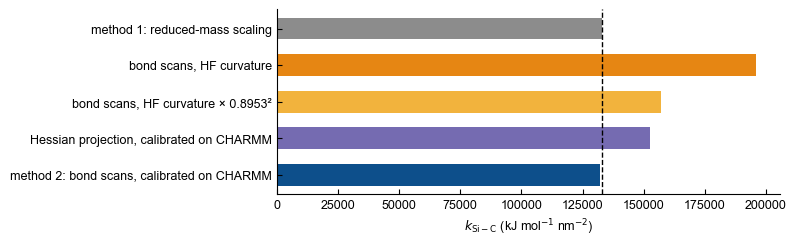

,k (kJ/mol/nm²),vs method 1 (%)
method 1: reduced-mass scaling,132906.0,0.0
"bond scans, HF curvature",196101.0,47.5
"bond scans, HF curvature × 0.8953²",157187.0,18.3
"Hessian projection, calibrated on CHARMM",152521.0,14.8
"method 2: bond scans, calibrated on CHARMM",132117.0,-0.6


In [16]:
table = pd.DataFrame({'k (kJ/mol/nm²)': [k_mass, k_hf_sic, k_scaled, k_seminario, k_scan]},
                     index=['method 1: reduced-mass scaling', 'bond scans, HF curvature', 'bond scans, HF curvature × 0.8953²',
                            'Hessian projection, calibrated on CHARMM', 'method 2: bond scans, calibrated on CHARMM'])
table['vs method 1 (%)'] = (table['k (kJ/mol/nm²)'] / k_mass - 1) * 100

fig, ax = plt.subplots(figsize=(6.5, 2.4))
ax.barh(table.index, table['k (kJ/mol/nm²)'], color=['0.55', '#E68613', '#F2B33D', '#756BB1', '#0D4F8B'], height=0.6)
ax.axvline(k_mass, color='black', ls='--', lw=1)
ax.invert_yaxis()
ax.set_xlabel(r'$k_{\rm Si-C}$ (kJ mol$^{-1}$ nm$^{-2}$)')
# fig.savefig('figures/k_si_c_estimates.pdf')
plt.show()

table.round({'k (kJ/mol/nm²)': 0, 'vs method 1 (%)': 1})

<h2 style="background-color:#2E7D57; color:#ffffff; padding:8px 14px; border-radius:6px;">Comparison: force constant of the Si–C bond<br><span style="font-size:0.72em; font-weight:normal;">the two methods</span></h2>

In [17]:
pd.DataFrame({'method 1: reduced-mass scaling': ['CHARMM C–C × μ(C–C)/μ(Si–C)', f'{mu_cc / mu_sic:.3f}', f'{k_mass:,.0f}', ''],
              'method 2: bond scans, calibrated on CHARMM': ['HF Si–C × CHARMM C–C / HF C₄–C₅', f'{k_hf_sic / k_hf_cc:.3f}',
                                                             f'{k_scan:,.0f}', f'{(k_scan / k_mass - 1) * 100:+.1f} %']},
             index=['k from', 'Si–C/C–C factor', 'k (kJ/mol/nm²)', 'difference'])

,method 1: reduced-mass scaling,"method 2: bond scans, calibrated on CHARMM"
k from,CHARMM C–C × μ(C–C)/μ(Si–C),HF Si–C × CHARMM C–C / HF C₄–C₅
Si–C/C–C factor,0.714,0.710
k (kJ/mol/nm²),"132,906","132,117"
difference,,-0.6 %


- The factor of reduced-mass scaling, $\mu_{\rm C-C}/\mu_{\rm Si-C} = 0.714$, is not a physical relation: with $k = \mu\omega^2$ [11], equal frequencies would give $\mu_{\rm Si-C}/\mu_{\rm C-C} = 1.40$.
- The bond scans give almost the same factor, so the two methods agree within 1 %.

<h2 style="background-color:#4A4E69; color:#ffffff; padding:8px 14px; border-radius:6px;">References</h2>

1. W. J. Hehre, R. Ditchfield, J. A. Pople, *J. Chem. Phys.* **56**, 2257–2261 (1972).
2. P. C. Hariharan, J. A. Pople, *Theor. Chim. Acta* **28**, 213–222 (1973).
3. F. Neese, *WIREs Comput. Mol. Sci.* **12**, e1606 (2022).
4. F. Neese, F. Wennmohs, U. Becker, C. Riplinger, *J. Chem. Phys.* **152**, 224108 (2020).
5. H. Nguyen, D. A. Case, A. S. Rose, *Bioinformatics* **34**, 1241–1242 (2018).
6. A. H. Larsen et al., *J. Phys.: Condens. Matter* **29**, 273002 (2017).
7. K. Vanommeslaeghe et al., *J. Comput. Chem.* **31**, 671–690 (2010).
8. P. Pulay, G. Fogarasi, G. Pongor, J. E. Boggs, A. Vargha, *J. Am. Chem. Soc.* **105**, 7037–7047 (1983).
9. A. P. Scott, L. Radom, *J. Phys. Chem.* **100**, 16502–16513 (1996).
10. J. M. Seminario, *Int. J. Quantum Chem.* **60**, 1271–1277 (1996).
11. E. B. Wilson, J. C. Decius, P. C. Cross, *Molecular Vibrations*, McGraw-Hill, New York (1955).
